**Week 3 EDA: student math performance.** This notebook explores the cleaned math class dataset (`math_clean.csv`) from Week 2. Each row is one student, and there are 395 students in total. I look at absences, final grades (G3), study time and school, using a histogram, box plot, scatter plot, bar chart and heatmap. The question I'm trying to answer is what patterns show up in absences and final grade, and which unusual values need checking.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../outputs/math_clean.csv")
print(df.shape)
print(df.head())
print(df.dtypes)

(395, 36)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  Dalc Walc  health  absences  G1  G2  G3 passed grade_change absence_band  
0    1    1       3         6   5   6   6  False            1     moderate  
1    1    1       3         4   5   5   6  False            1          low  
2    2    3       3        10   7   8  10   True            3     moderate  
3    1    1       5         2  15  14  15   True            0          low  
4    1    2       5         4   6  10  10   True            4          low  

[5 rows x 36 columns]
school            

In [2]:
from pathlib import Path
print(Path.cwd())
for f in Path.cwd().rglob("*"):
    if f.suffix in [".csv", ".xlsx"] and "venv" not in f.parts:
        print(f)

C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\practice dataset in visualization


In [3]:
from pathlib import Path
root = Path.cwd().parent
for f in root.rglob("*"):
    if f.suffix in [".csv", ".xlsx"] and "venv" not in f.parts:
        print(f)

C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\outputs\math_clean.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\outputs\math_por_merged.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\outputs\summary_school_studytime.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\student_data\student-mat.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\student_data\student-por.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\da_venv\Lib\site-packages\tornado\test\csv_translations\fr_FR.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\da_venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccos.csv
C:\Users\TYCOON\Documents\data-science-lab\data-acquisition-and-manipulation\da_venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccosh.csv
C:\Users\

In [4]:
df = pd.read_csv("../outputs/math_clean.csv")
print(df.shape)
print(df.dtypes)

(395, 36)
school            str
sex               str
age             int64
address           str
famsize           str
Pstatus           str
Medu            int64
Fedu            int64
Mjob              str
Fjob              str
reason            str
guardian          str
traveltime      int64
studytime       int64
failures        int64
schoolsup         str
famsup            str
paid              str
activities        str
nursery           str
higher            str
internet          str
romantic          str
famrel          int64
freetime        int64
goout           int64
Dalc            int64
Walc            int64
health          int64
absences        int64
G1              int64
G2              int64
G3              int64
passed           bool
grade_change    int64
absence_band      str
dtype: object


In [5]:
print(df.isna().sum().sum())
print(df[["age", "absences", "G1", "G2", "G3"]].describe())

0
              age    absences          G1          G2          G3
count  395.000000  395.000000  395.000000  395.000000  395.000000
mean    16.696203    5.708861   10.908861   10.713924   10.415190
std      1.276043    8.003096    3.319195    3.761505    4.581443
min     15.000000    0.000000    3.000000    0.000000    0.000000
25%     16.000000    0.000000    8.000000    9.000000    8.000000
50%     17.000000    4.000000   11.000000   11.000000   11.000000
75%     18.000000    8.000000   13.000000   13.000000   14.000000
max     22.000000   75.000000   19.000000   19.000000   20.000000


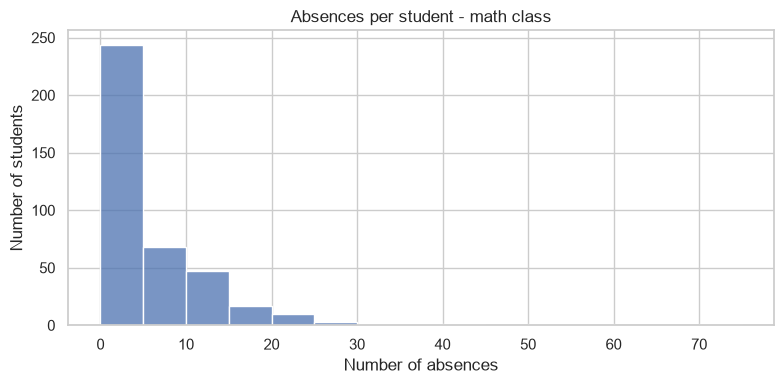

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="absences", bins=15, ax=ax)
ax.set(title="Absences per student - math class",
       xlabel="Number of absences", ylabel="Number of students")
plt.tight_layout()
plt.show()

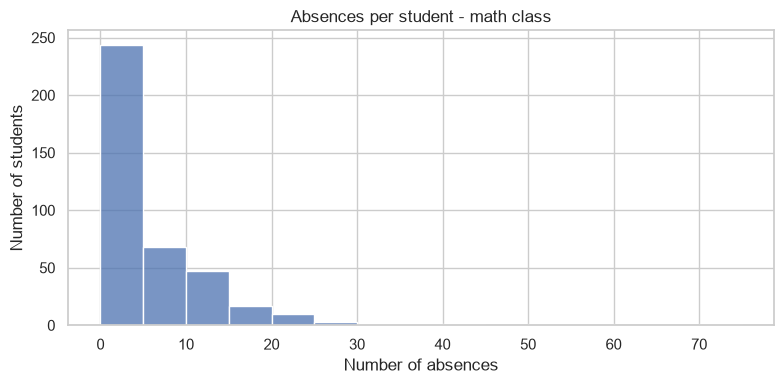

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="absences", bins=15, ax=ax)
ax.set(title="Absences per student - math class",
       xlabel="Number of absences", ylabel="Number of students")
plt.tight_layout()
plt.show()

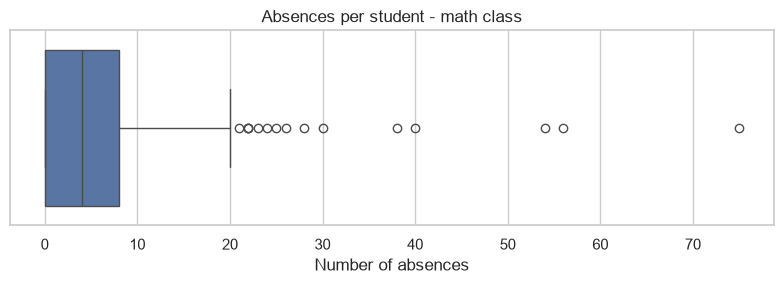

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(data=df, x="absences", ax=ax)
ax.set(title="Absences per student - math class",
       xlabel="Number of absences")
plt.tight_layout()
plt.show()

In [9]:
q1, q3 = df["absences"].quantile([.25, .75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
flagged = df[df["absences"] > upper]
print(q1, q3, iqr, upper)
print(len(flagged))
print(flagged["absences"].sort_values().tolist())

0.0 8.0 8.0 20.0
15
[21, 22, 22, 22, 23, 24, 25, 26, 28, 30, 38, 40, 54, 56, 75]


In [10]:
print("Mean all:", df["absences"].mean())
print("Mean without flagged:", df.loc[~df.index.isin(flagged.index), "absences"].mean())
print("Median all:", df["absences"].median())
print("Median without flagged:", df.loc[~df.index.isin(flagged.index), "absences"].median())

Mean all: 5.708860759493671
Mean without flagged: 4.602631578947369
Median all: 4.0
Median without flagged: 3.0


In [11]:
print(df["school"].value_counts())
print(df.groupby("school")["absences"].agg(["count", "mean", "median"]))

school
GP    349
MS     46
Name: count, dtype: int64
        count      mean  median
school                         
GP        349  5.965616     4.0
MS         46  3.760870     3.0


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../outputs/math_clean.csv")
print(df.shape)

(395, 36)


In [13]:
print(df["school"].value_counts())
print(df.groupby("school")["absences"].agg(["count", "mean", "median"]))

school
GP    349
MS     46
Name: count, dtype: int64
        count      mean  median
school                         
GP        349  5.965616     4.0
MS         46  3.760870     3.0


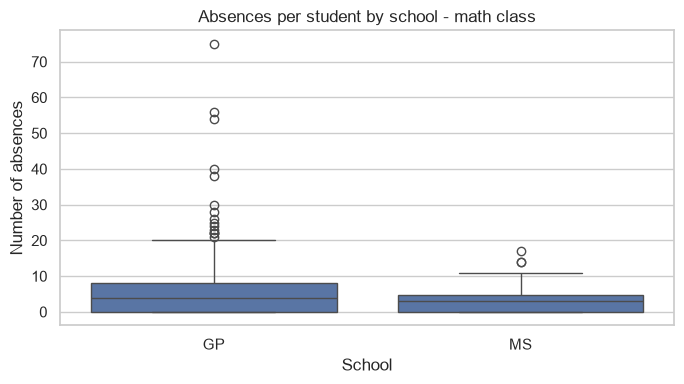

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="school", y="absences", ax=ax)
ax.set(title="Absences per student by school - math class",
       xlabel="School", ylabel="Number of absences")
plt.tight_layout()
plt.show()

In [15]:
print(df.groupby("school")["absences"].quantile([.25, .5, .75]).unstack())

        0.25  0.50  0.75
school                  
GP       0.0   4.0  8.00
MS       0.0   3.0  4.75


In [16]:
df["high_absence"] = df["absences"] > 20
print(df.groupby("school")["high_absence"].agg(["sum", "count", "mean"]))

        sum  count     mean
school                     
GP       15    349  0.04298
MS        0     46  0.00000


In [17]:
df["high_absence"] = df["absences"] > 20
print(df.groupby("school")["high_absence"].agg(["sum", "count", "mean"]))

        sum  count     mean
school                     
GP       15    349  0.04298
MS        0     46  0.00000


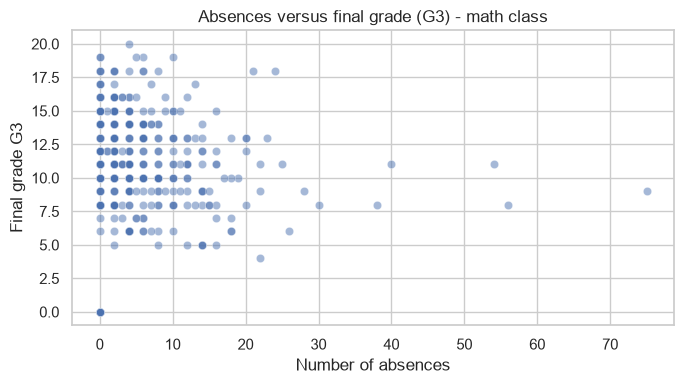

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.5, ax=ax)
ax.set(title="Absences versus final grade (G3) - math class",
       xlabel="Number of absences", ylabel="Final grade G3")
plt.tight_layout()
plt.show()

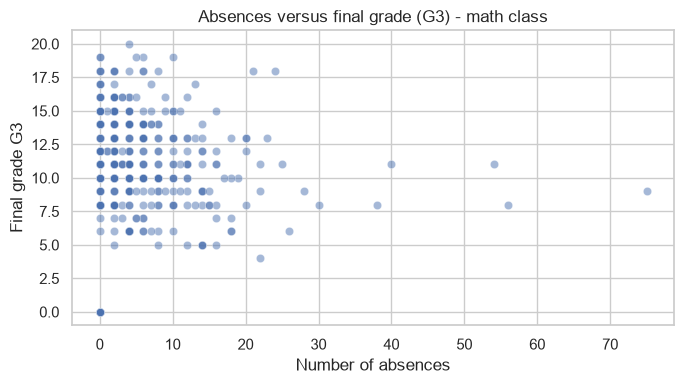

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.5, ax=ax)
ax.set(title="Absences versus final grade (G3) - math class",
       xlabel="Number of absences", ylabel="Final grade G3")
plt.tight_layout()
plt.show()

In [20]:
print(df[["absences", "G3"]].corr(method="pearson"))
print(df[["absences", "G3"]].corr(method="spearman"))
print((df["G3"] == 0).sum())

          absences        G3
absences  1.000000  0.034247
G3        0.034247  1.000000
          absences        G3
absences  1.000000  0.017731
G3        0.017731  1.000000
38


   studytime  students    mean_G3  median_G3
0          1       105  10.047619       10.0
1          2       198  10.171717       11.0
2          3        65  11.400000       12.0
3          4        27  11.259259       12.0


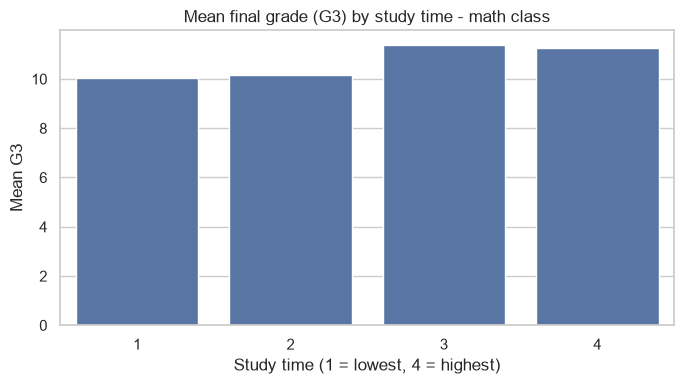

In [21]:
summary = df.groupby("studytime", as_index=False).agg(
    students=("G3", "size"),
    mean_G3=("G3", "mean"),
    median_G3=("G3", "median")
)
print(summary)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=summary, x="studytime", y="mean_G3", ax=ax)
ax.set(title="Mean final grade (G3) by study time - math class",
       xlabel="Study time (1 = lowest, 4 = highest)", ylabel="Mean G3")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

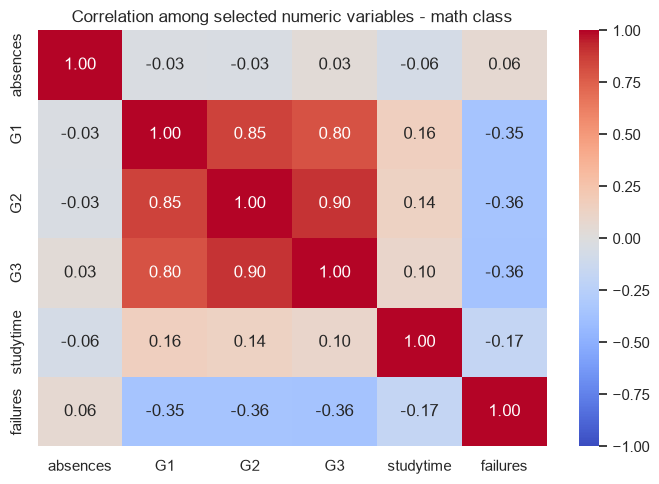

In [22]:
cols = ["absences", "G1", "G2", "G3", "studytime", "failures"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set(title="Correlation among selected numeric variables - math class")
plt.tight_layout()
plt.show()


 **Figure 5. Heatmap of correlations (math class, n = 395).**
Observation: G2 and G1 are strongly correlated with G3 (0.90 and 0.80), while absences show almost no correlation (0.03). Interpretation: earlier grades track the final grade closely, and past failures are moderately linked to lower grades. Limitation: correlations show that variables move together but cannot show that one causes the other; this data covers 395 students from two schools only.

Figure 1. Histogram of absences per student (math class, n = 395). Observation: Most students had few absences (median 4), but a small group had many, with a maximum of 75. Interpretation: the long tail pulls the mean (5.71) above the median, so the median is a better description of a typical student. Limitation: 15 students with more than 20 absences were flagged as unusual but not checked against source records, so we can’t say whether they are errors or real cases.

Figure 2. Box plot of absences per student (math class, n = 395). Most students had between 0 and 8 absences, and the typical student (the median) had 4. Fifteen students had more than 20 absences, which is well above everyone else. They stand out, but that doesn’t mean the records are wrong. A student could have been ill for a long time, for example. The box plot only marks values as unusual. It can’t tell me whether they are real or mistakes, so I would need to check the source records before changing or removing anything.

Figure 4. Bar chart of mean final grade (G3) by study time (math class, n = 395). Students who studied more tended to have slightly higher final grades. The average went from about 10.05 for study time 1 to 11.40 for study time 3. The gap is small, only about 1.4 points on a 0 to 20 scale. Study time 4 dips a little to 11.26, but only 27 students are in that group, so I wouldn’t read much into it. This chart shows that study time and grades go together a bit, not that studying more causes better grades. Other things, like past failures, could be part of the story.

**Summary of findings**

Most students had few absences (median 4), but 15 of the 395 students had more than 20, with a maximum of 75. These stand out as unusual, so I flagged them instead of removing them. Removing them would have lowered the mean from 5.71 to 4.60.

Final grades were strongly linked to earlier grades (G2 and G3: 0.90, G1 and G3: 0.80), and moderately linked to past failures (-0.36). Absences showed almost no link to final grade (0.03), and study time only a weak one (0.10). Mean grade rose slightly from study time 1 to study time 3, though study time 4 has only 27 students.

**Limitations:** these are associations, not causes. Thirty-eight students have a final grade of 0, and I can't tell from the data whether they scored zero or missed the exam. The MS school has only 46 students, so comparisons with GP should be read carefully. Flagged values were not checked against source records.

**Next steps:** check the 15 high-absence students and the 38 zero grades against the source records, then complete the peer review.